# Bài tập thực hành 2
Xây dựng mô hình Naïve ngây thơ trên tập dữ liệu mushroom.

## Khai báo thư viện

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

## Đọc và phân tích dữ liệu

In [3]:
df = pd.read_csv("data/mushrooms.csv")
df.columns = df.columns.str.strip()

print(df.head())
print(df.shape)
print(df.columns.tolist())
print(df["class"].value_counts())

  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w         p          w   
1       

## Xử lý dữ liệu thiếu và tách đầu vào

In [6]:
df = df.replace("?", np.nan)
df = df.dropna(subset=["class"])

X = df.drop(columns=["class"])
y = df["class"].map({
    "e": "Edible",
    "p": "Poisonous"
})

print("Các lớp:")
print(y.value_counts())

Các lớp:
class
Edible       4208
Poisonous    3916
Name: count, dtype: int64


## Chia tập train/test

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Số mẫu huấn luyện:", len(X_train))
print("Số mẫu kiểm tra:", len(X_test))

Số mẫu huấn luyện: 6499
Số mẫu kiểm tra: 1625


## Mã hóa và huấn luyện Naive Bayes

In [10]:
nb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ("classifier", MultinomialNB())
])

nb_model.fit(X_train, y_train)

print("Đã huấn luyện xong Naive Bayes.")

Đã huấn luyện xong Naive Bayes.


## Dự đoán và đánh giá

Accuracy: 0.947076923076923
              precision    recall  f1-score   support

      Edible       0.91      0.99      0.95       842
   Poisonous       0.99      0.90      0.94       783

    accuracy                           0.95      1625
   macro avg       0.95      0.95      0.95      1625
weighted avg       0.95      0.95      0.95      1625



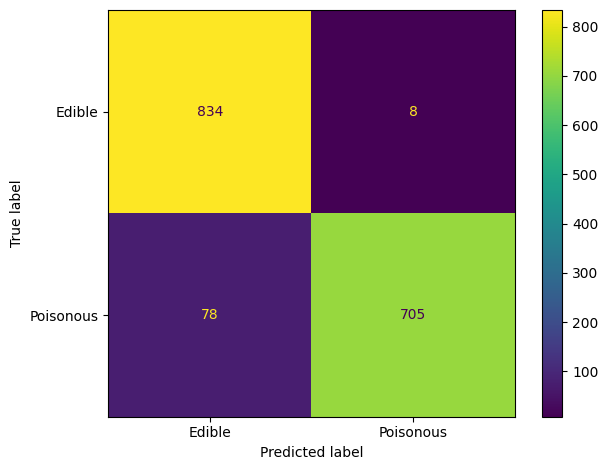

In [11]:
y_pred = nb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Edible", "Poisonous"]
)

plt.tight_layout()
plt.show()